# DHI MIKE DFSU results with pyramids-mesh

**DFSU** is DHI's flexible-mesh format for MIKE 21/3 hydrodynamic results. It stores an unstructured mesh (mixed triangles and quads) with time-varying variables such as surface elevation and depth-averaged velocity. pyramids-mesh reads it through `mikeio` under the hood and presents a standard `UgridDataset`.

## Setup

In [1]:
import os
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display

def show():
    """Embed the current matplotlib figure as a PNG (Agg draws nothing on its own)."""
    from io import BytesIO
    buf = BytesIO()
    plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all"); buf.seek(0)
    display(Image(data=buf.read()))

In [2]:
from pathlib import Path
import numpy as np
from pyramids.netcdf.ugrid import UgridDataset

# Paths are relative to THIS notebook (docs/examples/), never the repo root.
# read_file takes a pathlib.Path - pass Path objects, never str().
DATA = Path("../../examples/data")
DATA.resolve()

WindowsPath('C:/python-environments/worktrees/pyramids-mesh/example-notebooks/examples/data')

## What is on disk

In [3]:
for p in sorted((DATA / "dhi").iterdir()):
    print(p.name, f"({p.stat().st_size:,} bytes)")

OdenseHD2D.dfsu (144,530 bytes)


## Quickstart read

Pass `driver="dfsu"`. This is the classic MIKE *OdenseHD2D* estuary example - 535 nodes, 724 faces.

In [4]:
ds = UgridDataset.read_file(DATA / "dhi" / "OdenseHD2D.dfsu", driver="dfsu")
ds

UgridDataset(mesh='mesh2d', n_node=535, n_face=724, n_edge=0, variables=['Surface elevation', 'Depth averaged U velocity', 'Depth averaged V velocity', 'node_z'])

The variables are `Surface elevation` and the two depth-averaged velocity components (`Depth averaged U/V velocity`), plus the static bed level `node_z`.

## Explore the dataset

A `UgridDataset` wraps a UGRID-style unstructured mesh plus any data variables that ride on it. The scalar properties below describe the grid at a glance: how many nodes and faces it has, its coordinate reference system, and its spatial extent.

The coordinates are a projected UTM grid (metres), even though no CRS is embedded.

In [5]:
print("n_node:", ds.n_node)
print("n_face:", ds.n_face)
print("crs:   ", ds.crs)
print("epsg:  ", ds.epsg)
print("bounds:", ds.bounds)  # (xmin, ymin, xmax, ymax)

n_node: 535
n_face: 724
crs:    None
epsg:   None
bounds: (211068.5, 6153077.5, 224171.625, 6164499.5)


`crs`/`epsg` are often `None`: many hydraulic-model result files store coordinates without an embedded CRS, so pyramids reports the geometry faithfully and leaves georeferencing to you. The `bounds` tuple is the mesh envelope in the file's own coordinate units.

### Data variables

`data_variable_names` lists every field attached to the mesh. These are the real model results - water levels, depths, velocities - that make a results file worth reading.

In [6]:
ds.data_variable_names

['Surface elevation',
 'Depth averaged U velocity',
 'Depth averaged V velocity',
 'node_z']

`summary()` returns a tidy `pandas.DataFrame` of per-variable statistics (count, min, max, mean, std) - a quick sanity check on magnitudes and fill values.

In [7]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
Surface elevation,9395,-0.247714,0.444137,0.143018,0.179092
Depth averaged U velocity,9395,-0.322162,0.307246,0.013443,0.051201
Depth averaged V velocity,9395,-0.634840,1.071846,0.012656,0.057671
node_z,535,-11.131345,-0.200000,-3.595227,2.870370


## The Mesh2d geometry

`ds.mesh` is a `Mesh2d`: the topology the data variables are defined on. Nodes carry the `(x, y)` coordinates; `face_node_connectivity` says which nodes form each face (a row per face, padded to the maximum vertex count).

In [8]:
mesh = ds.mesh
nx, ny = np.asarray(mesh.node_x), np.asarray(mesh.node_y)
fnc = np.asarray(mesh.face_node_connectivity.data)
print("node_x:", nx.shape, " node_y:", ny.shape)
print("face_node_connectivity:", fnc.shape, " (n_face, max_vertices)")
fnc[:3]

node_x: (535,)  node_y: (535,)
face_node_connectivity: (724, 4)  (n_face, max_vertices)


array([[ 0,  1,  2, -1],
       [ 3,  1,  0, -1],
       [ 1,  3,  4, -1]])

`face_areas` gives the area of every face; `face_centroids` is a `(2, n_face)` array of face centre coordinates. Both are derived straight from the topology.

In [9]:
areas = np.asarray(mesh.face_areas)
cen = np.asarray(mesh.face_centroids)  # shape (2, n_face)
print("face_areas:", areas.shape, " mean area:", round(float(areas.mean()), 4))
print("face_centroids:", cen.shape)

face_areas: (724,)  mean area: 95242.3212
face_centroids: (2, 724)


## Wireframe - the bare mesh

`plot_outline()` draws the mesh edges with no data colouring. It is the fastest way to see the grid's shape, resolution, and how faces are distributed before looking at any results.

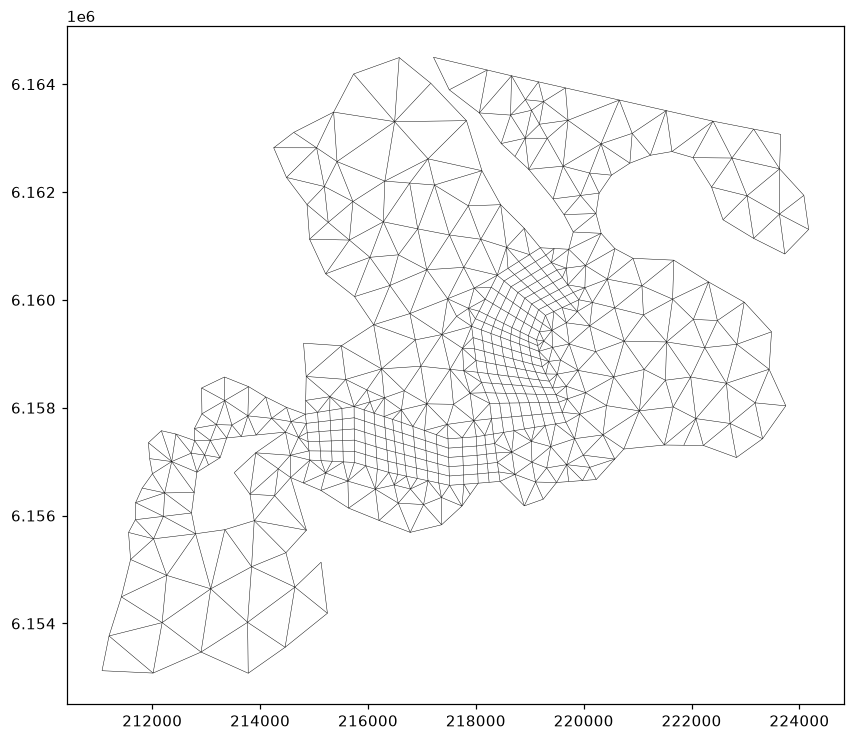

In [10]:
ds.plot_outline()
show()

## Mapping the real results

`Surface elevation` and the velocity components are time-varying (`time_values` lists the stored times, in seconds since the start). We pick a mid-simulation step with `isel` and map the tide level and the U-velocity.

In [11]:
print("n timesteps:", len(ds.time_values))
step = ds.isel(time=6)  # a mid-run snapshot

n timesteps: 13


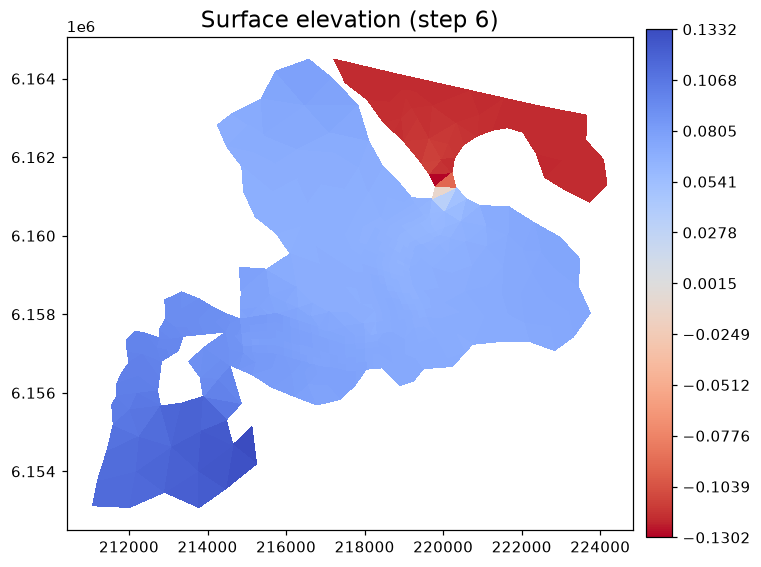

In [12]:
step.plot("Surface elevation", cmap="viridis", colorbar=True, title="Surface elevation (step 6)")
show()

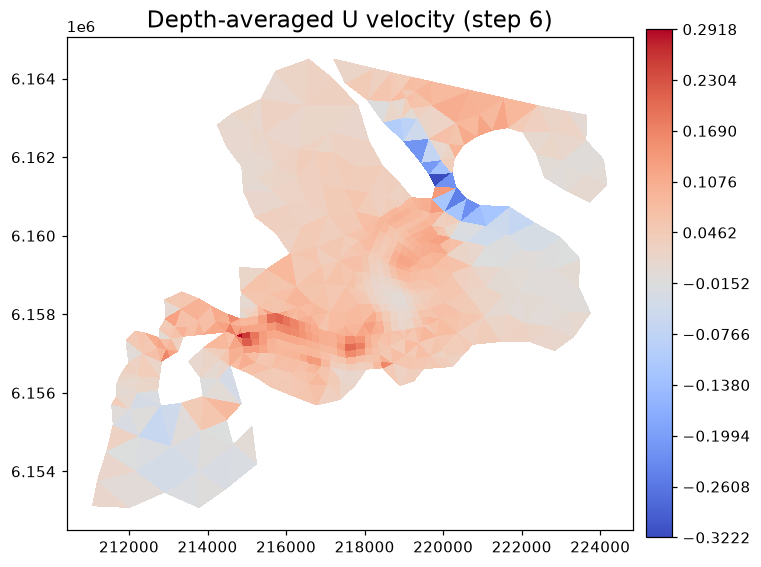

In [13]:
step.plot("Depth averaged U velocity", cmap="coolwarm", colorbar=True, title="Depth-averaged U velocity (step 6)")
show()

## From mesh to GIS

A `UgridDataset` is not a dead end - it converts into the vector and raster types the rest of a GIS workflow expects. Everything below is reached through pyramids; this package only supplies the file-format driver that built the mesh.

### Faces as vector polygons

`to_geodataframe(variable_name=...)` turns every face into a polygon row carrying that variable's value - a standard GeoPandas `GeoDataFrame` you can join, filter, or export.

In [14]:
gdf = step.to_geodataframe(variable_name="Surface elevation")
print("rows:", len(gdf), " columns:", list(gdf.columns), " crs:", gdf.crs)
gdf.head()

rows: 724  columns: ['Surface elevation', 'geometry']  crs: None


,Surface elevation,geometry
0,-0.120784,"POLYGON ((222397.938 6163314, 221635.719 61627..."
1,-0.120412,"POLYGON ((221528.844 6163509.5, 221635.719 616..."
2,-0.120513,"POLYGON ((221635.719 6162750.5, 221528.844 616..."
3,-0.130244,"POLYGON ((219634.297 6161580.5, 219805.859 616..."
4,-0.116005,"POLYGON ((220286.266 6161979, 220514.297 61623..."


Plotting that `GeoDataFrame` straight through GeoPandas (matplotlib under the hood) gives a choropleth of the same values, now as independent vector features.

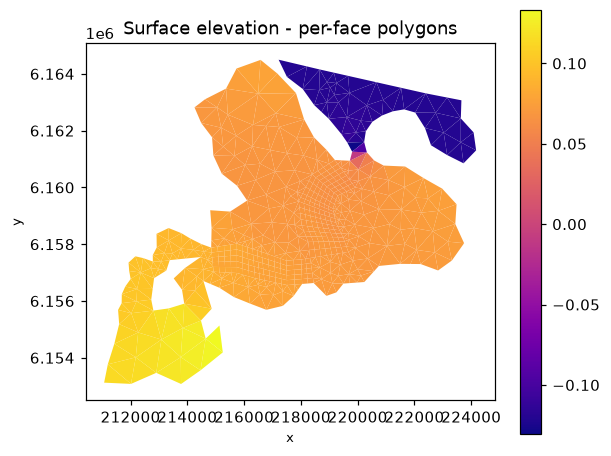

In [15]:
gdf.plot(column="Surface elevation", cmap="plasma", legend=True, figsize=(6, 5))
plt.title("Surface elevation - per-face polygons")
show()

### Dissolving into zones

`polygonize(variable)` merges neighbouring faces that share a value into larger polygons - handy for turning a noisy per-cell field into clean zones. It needs a single value per face, which is exactly what our working dataset holds.

dissolved polygons: 724  columns: ['value', 'geometry']


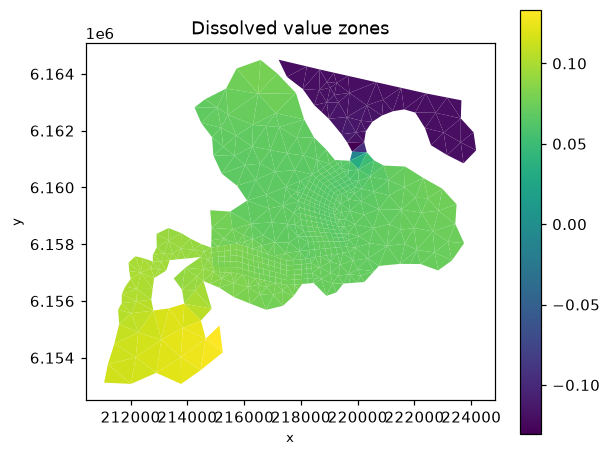

In [16]:
zones = step.polygonize("Surface elevation")
print("dissolved polygons:", len(zones), " columns:", list(zones.columns))
zones.plot(column="value", cmap="viridis", legend=True, figsize=(6, 5))
plt.title("Dissolved value zones")
show()

### Sampling at points

`sample(variable, x, y)` reads the value of the face that contains each query point. Here we probe the first few face centroids, so each query lands squarely inside a face.

In [17]:
cen = np.asarray(ds.mesh.face_centroids)
xs, ys = cen[0][:5], cen[1][:5]
vals = step.sample("Surface elevation", xs, ys)
for x, y, v in zip(xs, ys, np.asarray(vals)):
    print(f"({x:10.2f}, {y:10.2f}) -> {float(v):.4f}")

( 222020.13, 6162900.67) -> -0.1208
( 221854.17, 6163191.33) -> -0.1204
( 221466.51, 6162980.50) -> -0.1205
( 219889.09, 6161480.17) -> -0.1302
( 220303.42, 6162214.50) -> -0.1160


### The mesh outline as one polygon

`bounding_polygon()` returns a single shapely polygon tracing the mesh's outer boundary - the model's wetted footprint, useful as a clip mask or extent reference.

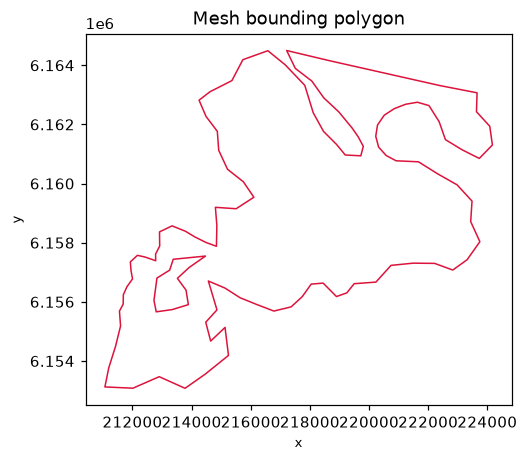

In [18]:
poly = ds.bounding_polygon()
import geopandas as gpd
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="crimson", figsize=(5, 5))
plt.title("Mesh bounding polygon")
show()

### Cropping to a sub-region

`subset_by_bounds(xmin, ymin, xmax, ymax)` returns a new, smaller `UgridDataset` holding only the faces inside the box - the same object type, so every operation above still applies. We derive a box from the mesh envelope so it works on any extent.

faces in full mesh: 724  -> in subset: 234


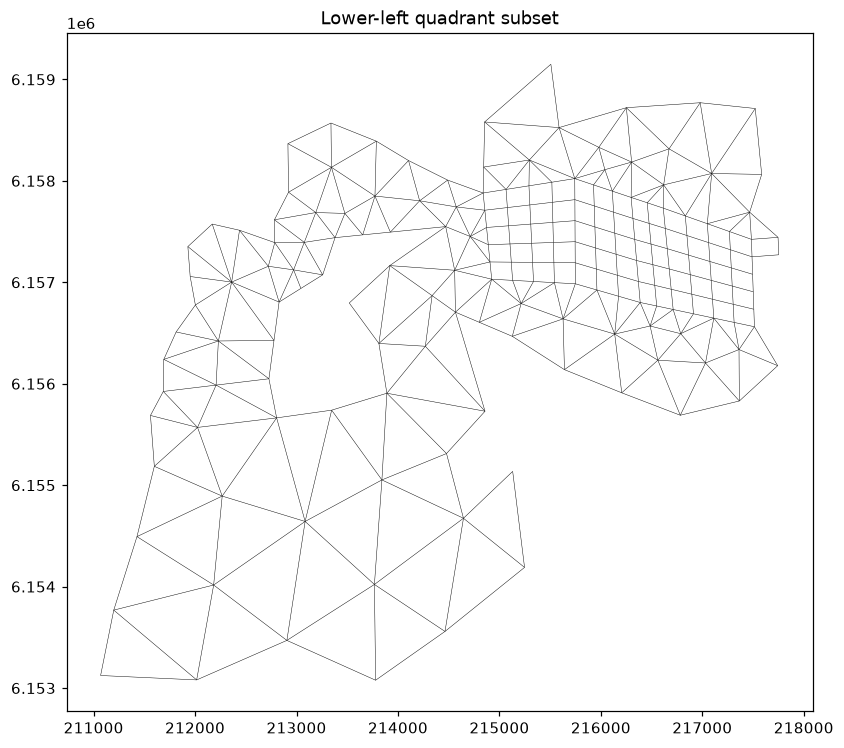

In [19]:
xmin, ymin, xmax, ymax = ds.bounds
mx, my = (xmin + xmax) / 2, (ymin + ymax) / 2
sub = ds.subset_by_bounds(xmin, ymin, mx, my)
print("faces in full mesh:", ds.n_face, " -> in subset:", sub.n_face)
sub.plot_outline()
plt.title("Lower-left quadrant subset")
show()

### Connectivity as a sparse graph

`sparse_adjacency()` exposes face-to-face adjacency as a SciPy sparse matrix, and `connected_components()` labels each face by which connected piece of the mesh it belongs to - the entry points for graph algorithms over the grid.

In [20]:
adj = ds.sparse_adjacency()
print("adjacency:", adj.shape, " non-zeros:", adj.nnz)
labels = ds.connected_components()
print("connected components:", len(np.unique(np.asarray(labels))))

adjacency: (724, 724)  non-zeros: 2248
connected components: 1


### Circumcenters - not applicable here

`circumcenters()` is only defined for purely triangular meshes. This grid contains quad (or mixed-polygon) faces, so the call would raise `ValueError`. We note it and skip rather than force it.

### Self-contained rasterisation

`to_dataset(variable, cell_size=...)` samples the mesh onto a regular raster grid and returns a pyramids `Dataset`. Unlike `rasterize_like` / `regrid` - which need an existing reference grid and are therefore skipped here - this is self-contained: you only choose a cell size.

rasterised to: Dataset


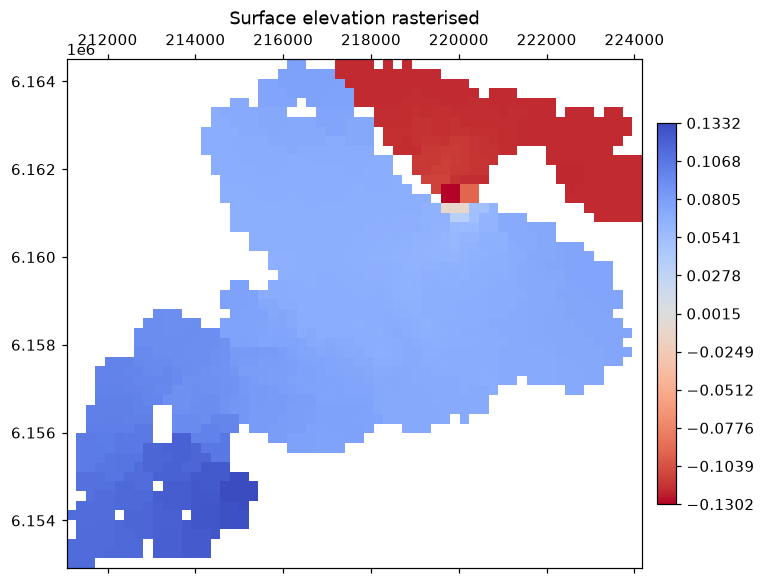

In [21]:
step_xy = (ds.bounds[2] - ds.bounds[0]) / 60
rast = step.to_dataset("Surface elevation", cell_size=step_xy)
print("rasterised to:", type(rast).__name__)
rast.plot()
plt.title("Surface elevation rasterised")
show()

### Reprojection - skipped

`to_crs(...)` needs a *source* CRS to project from. MIKE stores the projection in a side file, so `ds.crs` comes back `None` here even though the coordinates are UTM metres. With no source CRS, reprojection is undefined, so we skip it; assign a CRS first if your coordinates are georeferenced.

### Back to xarray

`to_xarray()` hands the whole dataset back as an `xarray.Dataset`, so you can drop into the full xarray ecosystem (time selection, resampling, NetCDF export) whenever you need it.

In [22]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.data_vars)[:6]

('Dataset',
 ['mesh2d',
  'mesh2d_node_x',
  'mesh2d_node_y',
  'mesh2d_face_nodes',
  'mesh2d_face_x',
  'mesh2d_face_y'])

## Takeaway

DFSU brings DHI's flexible mesh into the same `UgridDataset` shape as every other driver. Its mixed triangle/quad topology rules out `circumcenters()`, but surface elevation and velocity map cleanly once a timestep is selected, and the vector/raster conversions behave identically. pyramids-mesh owns only the DFSU parsing; the analysis lives in pyramids.